In [5]:
from tqdm import tqdm
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
import pymannkendall as mk
import statsmodels.api as sm
import xskillscore as xs
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import os,sys,glob
sys.path.insert(0,'/home/mingyu_seong/Works/func/python')
import mg

In [6]:
#--- Random seeds (42, 500, 123, 1000, 5473)
rs = 100

#--- Period
syr = 2001
eyr = 2024
nyr = eyr - syr + 1
tim = 'mon'

#--- Analysis period
csyr = 2007
ceyr = 2008
# csyr = 2001
# ceyr = 2024

#--- Read file
idir = '../../../../_nc/prediction/OBS/GPP/background/'
fin = 'predicted_GPP_'+tim+'_FFNN_' + str(syr) + '-' +  str(eyr) + '_seed' + str(rs) + '.nc'
ncid = xr.open_dataset(idir+fin)
raw = ncid['raw'].sel(time=slice(str(csyr),str(ceyr)))
pred = ncid['pred'].sel(time=slice(str(csyr),str(ceyr)))
ncid.close() ; del ncid

#--- Annual mean from monthly data
if tim == 'yr':
    ann_raw = raw.copy()
    ann_pred = pred.copy()
if tim == 'mon':
    mon_raw = raw.copy()
    mon_pred = pred.copy()
    nan_rows = np.isnan(mon_pred)
    mon_raw[np.where(nan_rows)[0]] = np.nan
    
    ann_raw  = mon_raw.groupby('time.year').mean()
    ann_pred = mon_pred.groupby('time.year').mean()
del raw, pred

### Monthly analysis

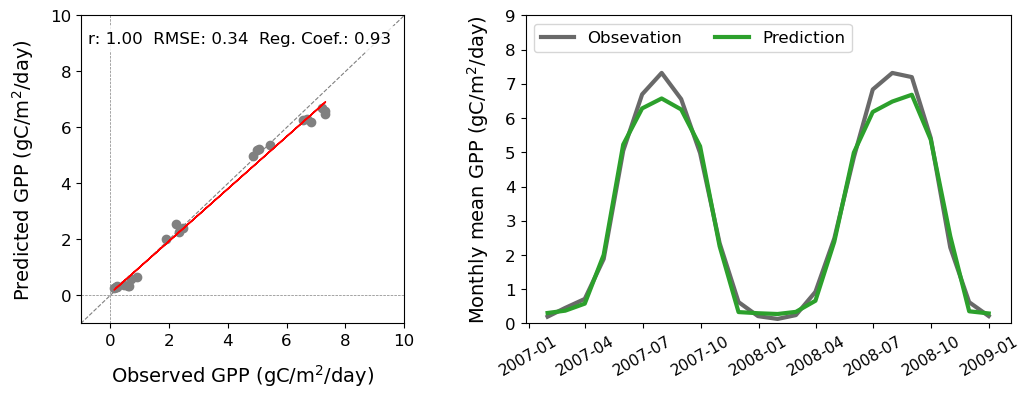

In [13]:
#--- Evaluation
raw = mon_raw[~nan_rows]
pred = mon_pred[~nan_rows]
X = raw.data.reshape(-1, 1)  # 2D 배열로 변환
y = pred.data
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)

rmse_wo = f"RMSE: {np.sqrt(np.mean((pred.data - raw.data) ** 2)):.2f}"
df = pd.DataFrame({'real': raw.data, 'pred': pred.data})
corr_wo = f"r: {df['real'].corr(df['pred']):.2f}" ; del df
reg_coef = f"Reg. Coef.: {reg.coef_[0]:.2f}"

#--- Plots
fig = plt.figure(figsize=(12, 4))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.5])  # 위:1, 아래:2

vmin = -1 ; vmax = 10
ax1 = fig.add_subplot(gs[0])
ax1.axvline(0, color='gray', linestyle='--', lw=0.5)
ax1.axhline(0, color='gray', linestyle='--', lw=0.5)
ax1.plot([vmin, vmax], [vmin, vmax], color='grey', linestyle='--', linewidth=0.8, label="1:1 Line")
ax1.scatter(raw.data, pred.data, color='grey', linestyle='-', linewidth=1)
ax1.plot(raw.data, y_pred, color='red', linestyle='-', linewidth=1, label="Linear Regression Line")
ax1.set_xlim(vmin, vmax)
ax1.set_ylim(vmin, vmax)
ax1.set_xlabel("Observed GPP (gC/m$^2$/day)",fontsize=14,labelpad=10)
ax1.set_ylabel("Predicted GPP (gC/m$^2$/day)",fontsize=14,labelpad=10)
ax1.tick_params(axis='both', labelsize=12)

textstr = corr_wo + '  ' + rmse_wo + '  ' + reg_coef
ax1.text(0.96, 0.90, textstr,  # 0.85, 0.93
        transform=ax1.transAxes,
        fontsize=12,
        verticalalignment='bottom',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='white', alpha=0.8))

# 2) Time series
x_dummy = raw.time
ax2 = fig.add_subplot(gs[1])

ax2.axhline(0, color='gray', linestyle='--', lw=0.5)
ax2.plot(x_dummy,raw, color='dimgrey', linestyle='-', linewidth=3, label="Obsevation")
ax2.plot(x_dummy,pred, color='tab:green', linestyle='-', linewidth=3, label="Prediction")
ax2.set_ylim(0, 9)
ax2.tick_params(axis='y', labelsize=12)
ax2.tick_params(axis='x', labelsize=11,rotation=30)
ax2.set_ylabel("Monthly mean GPP (gC/m$^2$/day)",fontsize=14,labelpad=10)
ax2.set_xlabel("",fontsize=14,labelpad=10)
ax2.legend(loc='upper left', ncol=3,fontsize=12)

plt.subplots_adjust(wspace=0.3) 
plt.show()